# Tile width toward Top-R

What happens as tiles shrink to one row, where Tiles equals Top-$R$?
Compare the fixed-budget ratio gap, selected runs, and short-run deficit.
Read the saved results from [02_02](02_02_global_oracle.ipynb) and
[02_03](02_03_selector_sweep.ipynb), generated from the same experiment.

This notebook runs independently of [02_04](02_04_analyze_oracle.ipynb),
which plots importance versus latency without requiring equal selected counts.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Inputs

Intervals are the saved maximal selected runs, with exclusive end indices.

In [2]:
reference = pd.read_csv("oracle_reference.csv", float_precision="round_trip")
selectors = pd.read_csv("selector_results.csv", float_precision="round_trip")
results = pd.concat([reference, selectors], ignore_index=True)

results["intervals"] = results.intervals.map(json.loads)
results["retained_pct"] = 100 * results.importance / results.importance_total.replace(0, np.nan)

## 2. Fixed-budget metrics

For maximal selected runs $\mathcal C(M)$ and boundary $s$ in rows,

$$D(M)=\sum_{C\in\mathcal C(M)}(s-|C|)_+,\qquad
L(M)=(b+\delta)|M|+\delta D(M).$$

At fixed row count, modeled latency differs only through the short-run deficit $D(M)$.

In [3]:
def geometry(row):
    lengths = np.array([end - start for start, end in row.intervals])
    return pd.Series({
        "R_selected": lengths.sum(),
        "chunks": len(lengths),
        "shortfall_rows": np.maximum(row.saturation_rows - lengths, 0).sum(),
    })

results = results.join(results.apply(geometry, axis=1))

For $\rho_M=I(M)/L(M)$ and oracle bounds $0<\ell\le\eta_R^\star\le u$,

$$g(M)=100\left(1-\frac{\rho_M}{\eta_R^\star}\right)
\le 100\left(1-\frac{\rho_M}{u}\right).$$

Report this upper bound, clipped at zero for numerical roundoff.
A fixed-budget gap requires exactly $R$ selected rows and positive oracle importance;
an underfilled Paper mask has no gap here.

In [4]:
bounds = results[["trace_id", "fraction"]].join(
    reference.set_index(["trace_id", "fraction"])[["eta_lower", "eta_upper"]],
    on=["trace_id", "fraction"],
    validate="many_to_one",
)
ratio = results.importance / results.latency.replace(0, np.nan)
comparable = (results.R_selected == results.R_nominal) & (bounds.eta_lower > 0)
results["gap_upper_pct"] = (
    100 * (1 - ratio / bounds.eta_upper.replace(0, np.nan))
).clip(lower=0).where(comparable)

## 3. Shrinking tiles

Within each shape, keep cases with a defined gap at every tile width.
Each case is a (trace, requested fraction) pair and has equal weight in the medians.
This comparison includes cases where Paper underfills. Width decreases left to right;
the red endpoint is Top-$R$ ($B=1$).

In [5]:
def match_cases(data):
    """Within each shape, keep cases with a defined gap for every method."""
    matched = []
    for _, group in data.groupby(["n", "d"]):
        gaps = group.pivot(
            index=["trace_id", "fraction"], columns="method", values="gap_upper_pct",
        )
        cases = gaps.dropna().index.to_frame(index=False)
        matched.append(group.merge(
            cases, on=["trace_id", "fraction"], how="inner", validate="many_to_one",
        ))
    return pd.concat(matched, ignore_index=True)

tiles = match_cases(results[results.tile_width.notna()])

In [6]:
granularity = tiles.groupby(["n", "d", "tile_width"]).agg(
    gap       = ("gap_upper_pct", "median"),
    runs      = ("chunks", "median"),
    shortfall = ("shortfall_rows", "median"),
    cases     = ("trace_id", "size"),
).reset_index()

granularity = granularity.sort_values(
    ["n", "d", "tile_width"],
    ascending=[True, True, False],
)

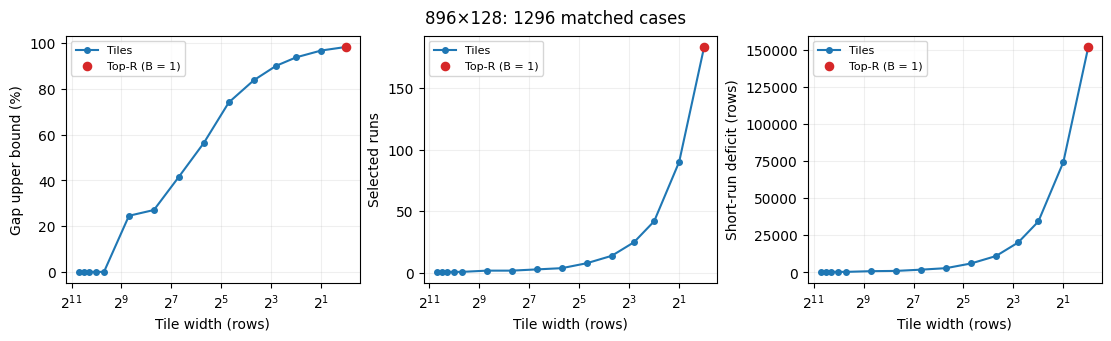

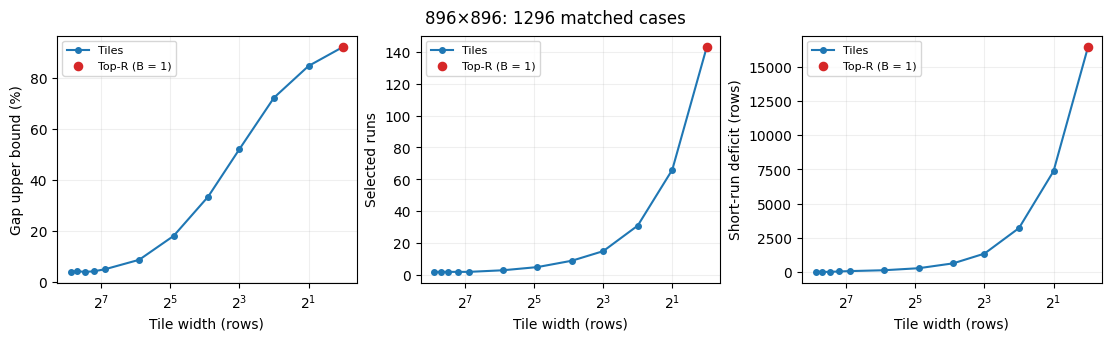

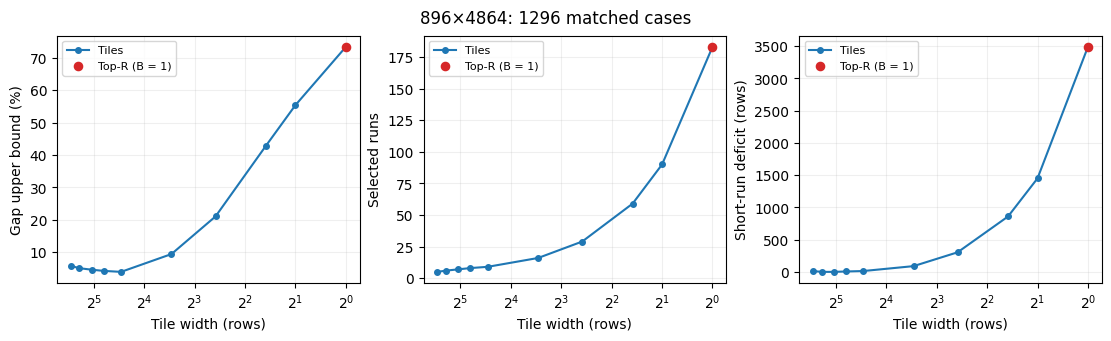

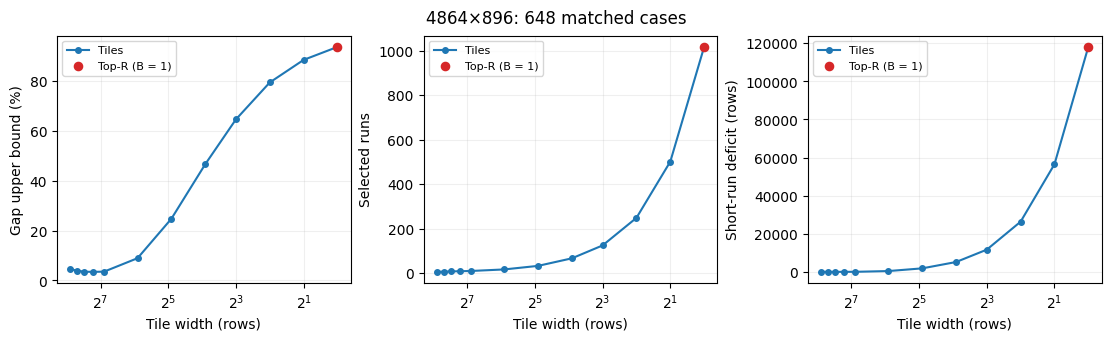

In [7]:
metrics = [
    ("gap", "Gap upper bound (%)"),
    ("runs", "Selected runs"),
    ("shortfall", "Short-run deficit (rows)"),
]

for (n, d), data in granularity.groupby(["n", "d"]):
    fig, axes = plt.subplots(
        1, 3,
        figsize=(11, 3.3),
        layout="constrained",
    )

    for ax, (metric, label) in zip(axes, metrics):
        ax.plot(data.tile_width, data[metric], "o-", markersize=4, label="Tiles")
        endpoint = data[data.tile_width == 1]
        ax.scatter(endpoint.tile_width, endpoint[metric], color="tab:red",
                   s=35, zorder=3, label="Top-R (B = 1)")
        ax.set(
            xlabel="Tile width (rows)",
            ylabel=label,
        )
        ax.set_xscale("log", base=2)
        ax.invert_xaxis()
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)

    fig.suptitle(f"{n}×{d}: {int(data.cases.iloc[0])} matched cases")
    plt.show()

In [8]:
width_records = []

for (n, d), data in granularity.groupby(["n", "d"]):
    best     = data[data.gap == data.gap.min()]
    endpoint = data[data.tile_width == 1]
    widths   = ", ".join(str(int(width)) for width in best.tile_width)

    width_records.append({
        "n"                   : n,
        "d"                   : d,
        "Cases per width"     : int(data.cases.iloc[0]),
        "Best width(s) (rows)" : widths,
        "Minimum gap (%)"     : best.gap.min(),
        "Top-R gap (%)"       : endpoint.gap.iloc[0] if len(endpoint) else np.nan,
    })

width_summary = pd.DataFrame(width_records).set_index(["n", "d"])
width_summary.round(3)

Cases per width         Best width(s) (rows)  Minimum gap (%)  \
n    d                                                                     
896  128              1296  1664, 1456, 1248, 1040, 832            0.000   
     896              1296                          179            4.058   
     4864             1296                           22            3.895   
4864 896               648                          149            3.436   

           Top-R gap (%)  
n    d                    
896  128          98.344  
     896          92.136  
     4864         73.397  
4864 896          93.828

## 4. Oracle and Paper references

Adding Paper requires matching again across **all** methods, excluding its
underfilled cases. The table shows how many cases remain. These medians can
differ from the tile-only medians above because they use a smaller set of cases.

In [9]:
BASELINES = {"Global DP": "black", "Paper greedy": "tab:orange"}

paired_results = match_cases(results)
paired_summary = paired_results.groupby(["n", "d", "method"]).agg(
    gap=("gap_upper_pct", "median"),
    tile_width=("tile_width", "first"),
    cases=("trace_id", "size"),
).reset_index()

recorded_counts = reference.groupby(["n", "d"]).size()
paired_counts = paired_results[paired_results.method == "Global DP"].groupby(["n", "d"]).size()
case_counts = pd.DataFrame({
    "Recorded cases": recorded_counts,
    "Paper gap cases": results[results.method == "Paper greedy"].groupby(["n", "d"]).gap_upper_pct.count(),
    "Matched cases": paired_counts.reindex(recorded_counts.index, fill_value=0),
    "Tile widths": selectors.groupby(["n", "d"]).tile_width.nunique(),
})
case_counts

Recorded cases  Paper gap cases  Matched cases  Tile widths
n    d                                                                
896  128             1296              144            144           15
     896             1296              432            432           12
     4864            1296             1296           1296           10
4864 896              648              144            144           12

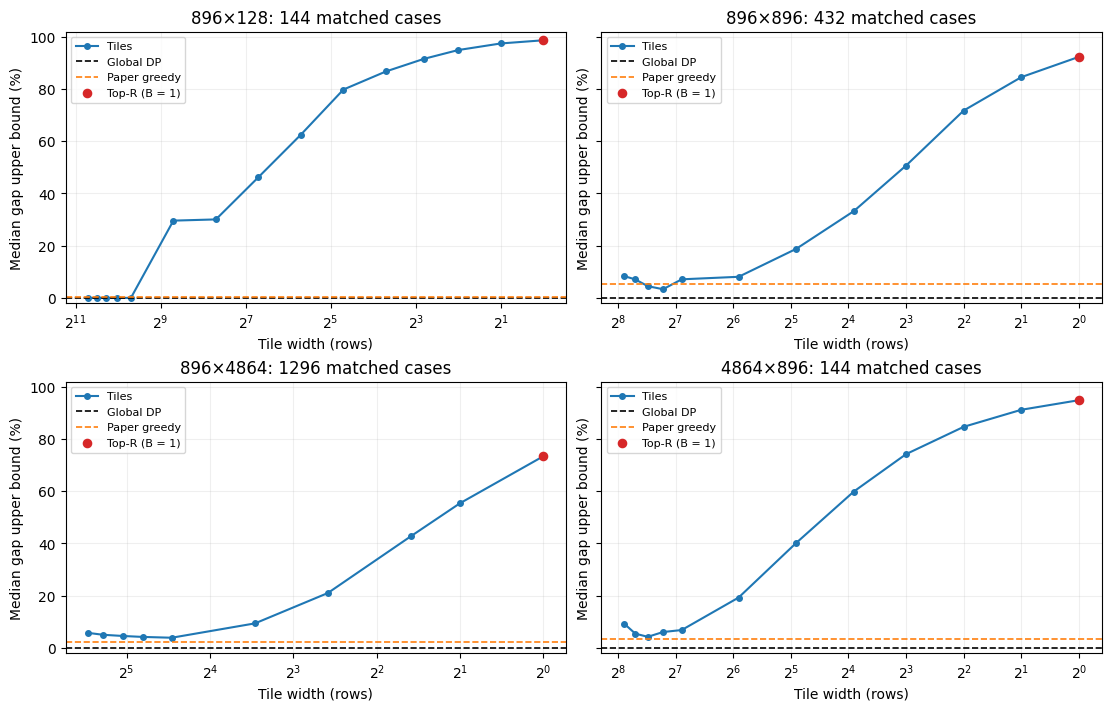

In [10]:
shapes = list(paired_summary.groupby(["n", "d"]))
fig, axes = plt.subplots(
    (len(shapes) + 1) // 2, 2,
    figsize=(11, 3.5 * ((len(shapes) + 1) // 2)),
    sharey=True,
    squeeze=False,
    layout="constrained",
)

for ax, ((n, d), data) in zip(axes.flat, shapes):
    widths = data[data.tile_width.notna()].sort_values(
        "tile_width", ascending=False,
    )
    ax.plot(
        widths.tile_width, widths.gap, "o-",
        color="tab:blue", markersize=4, label="Tiles",
    )

    for name, color in BASELINES.items():
        gap = data.loc[data.method == name, "gap"].iloc[0]
        ax.axhline(
            gap, color=color,
            linestyle="--", linewidth=1.2, label=name,
        )

    endpoint = widths[widths.tile_width == 1]
    ax.scatter(
        endpoint.tile_width, endpoint.gap,
        color="tab:red", s=35, zorder=3, label="Top-R (B = 1)",
    )
    ax.set(
        xlabel="Tile width (rows)",
        ylabel="Median gap upper bound (%)",
        title=f"{n}×{d}: {int(data.cases.iloc[0])} matched cases",
        ylim=(-2, 102),
    )
    ax.set_xscale("log", base=2)
    ax.invert_xaxis()
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(alpha=0.2)

for ax in list(axes.flat)[len(shapes):]:
    ax.set_visible(False)

plt.show()

## 5. Selected masks

Use the first trace and the requested fraction nearest $0.5$.
Tile widths decrease from top to bottom. Bright cells mark selected rows.
Show Paper's actual mask too; its gap stays undefined if it underfills.

In [11]:
first    = results[results.trace_id == results.trace_id.min()]
fraction = first.fraction.iloc[(first.fraction - 0.5).abs().argmin()]
example  = first[np.isclose(first.fraction, fraction)].set_index("method")

baselines = example.reindex(["Global DP", "Paper greedy"])
tile_masks = example[example.tile_width.notna()].sort_values(
    "tile_width",
    ascending=False,
)
example = pd.concat([baselines, tile_masks])

In [12]:
example[[
    "tile_width", "R_nominal", "R_selected", "retained_pct",
    "latency", "chunks", "shortfall_rows", "gap_upper_pct",
]].rename(columns={
    "tile_width"     : "Tile width",
    "R_nominal"      : "Requested rows",
    "R_selected"     : "Selected rows",
    "retained_pct"   : "Retained (%)",
    "latency"        : "Latency (ms)",
    "chunks"         : "Runs",
    "shortfall_rows" : "Deficit (rows)",
    "gap_upper_pct"  : "Gap upper bound (%)",
}).round(3)

,Tile width,Requested rows,Selected rows,Retained (%),Latency (ms),Runs,Deficit (rows),Gap upper bound (%)
method,,,,,,,,
Global DP,NaN,448,448.0,58.681,0.147,4.0,27.714,0.000
Paper greedy,NaN,448,448.0,58.604,0.148,4.0,36.571,0.747
Tiles (2s),238.0,448,448.0,53.549,0.144,2.0,0.000,6.941
Tiles (1.75s),208.0,448,448.0,55.243,0.153,2.0,86.857,9.601
Tiles (1.5s),179.0,448,448.0,54.760,0.147,2.0,28.857,6.758
Tiles (1.25s),149.0,448,448.0,54.808,0.156,3.0,117.857,12.141
Tiles (1s),119.0,448,448.0,55.616,0.147,4.0,27.857,5.233
Tiles (s/2^1),60.0,448,448.0,57.160,0.166,5.0,208.571,13.534
Tiles (s/2^2),30.0,448,448.0,59.236,0.196,8.0,502.857,24.240


In [13]:
masks = np.zeros((len(example), int(example.n.iloc[0])), dtype=bool)
for mask, intervals in zip(masks, example.intervals):
    for start, end in intervals:
        mask[start:end] = True

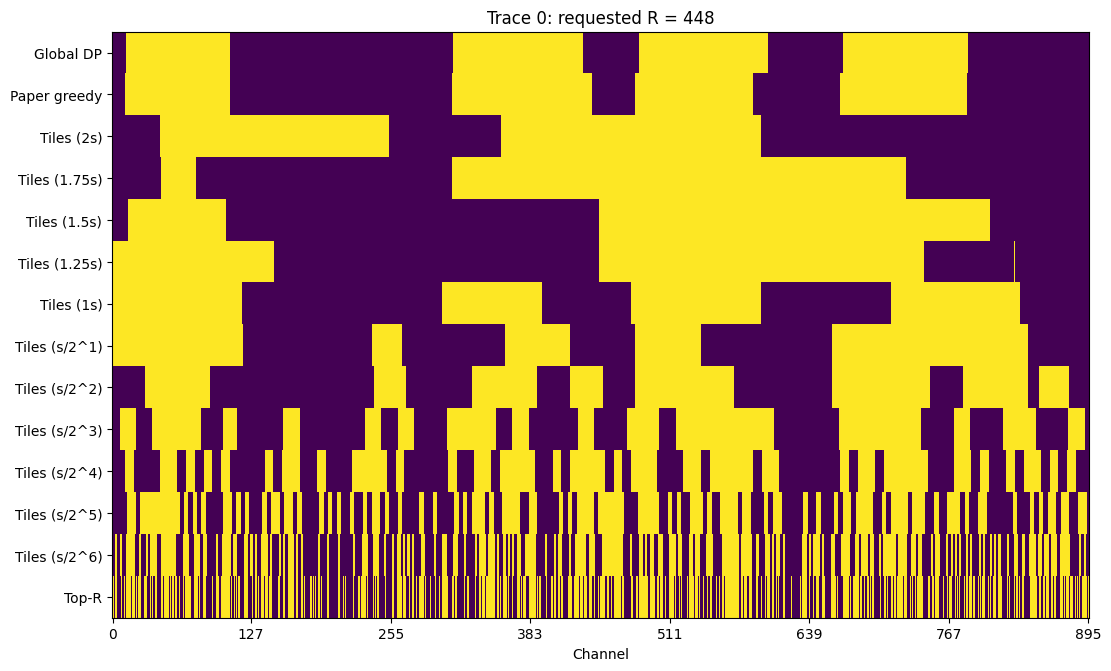

In [14]:
N = int(example.n.iloc[0])
R = int(example.R_nominal.iloc[0])
trace_id = int(example.trace_id.iloc[0])

fig, ax = plt.subplots(
    figsize=(11, 0.4 * len(example) + 1),
    layout="constrained",
)
ax.imshow(
    masks,
    aspect="auto",
    interpolation="nearest",
    cmap="viridis",
    vmin=0,
    vmax=1,
)
ax.set_yticks(range(len(example)), labels=example.index)
ax.set_xticks(np.linspace(0, N - 1, 8, dtype=int))
ax.set(
    xlabel="Channel",
    title=f"Trace {trace_id}: requested R = {R}",
)
plt.show()